# ESG and Corporate Financial Sustainability: Role of HRM and Corporate Governance
### Machine-learning classification of S&P 500 firms' ESG risk level

**Data:** `sp500_esg_ceo_info.csv` (503 firms, raw) and `sp500_esg_ceo_info-filtered.csv` (426 firms, cleaned, with `Year`).

**Task:** classify each firm into a **Low / Medium / High ESG-risk** category from its Governance, Environment and Social scores, the CEO's gender and the score year (governance and leadership variables from the paper's framework).

**Models (6):** Logistic Regression, Support Vector Machine, Neural Network (MLP), Random Forest, Gradient Boosting, and a **Stacking Ensemble** (new, best overall).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, StackingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

RANDOM_STATE = 42
pd.set_option("display.width", 140)
print("Libraries loaded.")

Libraries loaded.


## 1. Load the data

In [2]:
raw = pd.read_csv("sp500_esg_ceo_info.csv")
df  = pd.read_csv("sp500_esg_ceo_info-filtered.csv")

print("Raw file     :", raw.shape)
print("Filtered file:", df.shape)
df.head()

Raw file     : (503, 10)
Filtered file: (426, 11)


,Ticker,ESG Score,Governance Score,Environment Score,Social Score,ESG Score Date,ESG Status,CEO Full Name,CEO Gender,CEO Status,Year
0,MMM,33.61,7.72,12.33,13.56,01/08/2022,success,Mr. Michael F. Roman,male,success,22
1,AOS,25.43,6.27,7.29,11.87,01/01/2023,success,Mr. Kevin J. Wheeler,male,success,23
2,ABT,24.98,8.36,3.03,13.59,01/08/2022,success,Mr. Robert B. Ford,male,success,22
3,ABBV,27.84,9.95,1.12,16.77,01/08/2022,success,Mr. Richard A. Gonzalez,male,success,22
4,ACN,9.71,4.83,0.29,4.58,01/08/2022,success,Ms. Julie T. Spellman Sweet,female,success,22


In [3]:
print("Missing values per column (filtered file):")
print(df.isna().sum())
print()
print("Raw file: rows with a failed ESG lookup  :", raw["ESG Score"].isna().sum())
print("Raw file: rows with a failed CEO lookup  :", (raw["CEO Status"].str.contains("error", case=False, na=False)).sum())
df.describe().round(2)

Missing values per column (filtered file):
Ticker               0
ESG Score            0
Governance Score     0
Environment Score    0
Social Score         0
ESG Score Date       0
ESG Status           0
CEO Full Name        0
CEO Gender           0
CEO Status           0
Year                 0
dtype: int64

Raw file: rows with a failed ESG lookup  : 60
Raw file: rows with a failed CEO lookup  : 1


,ESG Score,Governance Score,Environment Score,Social Score,Year
count,426.00,426.00,426.00,426.00,426.00
mean,21.54,6.71,5.76,9.07,22.56
std,7.15,2.18,5.31,3.77,0.50
min,6.84,3.08,0.00,1.11,22.00
25%,16.00,5.23,1.58,6.66,22.00
50%,21.32,6.20,3.76,8.76,23.00
75%,26.20,7.73,9.18,11.51,23.00
max,46.02,15.51,24.61,21.01,23.00


## 2. Cleaning check
The filtered file should equal the raw file after dropping firms with no ESG score or no CEO record, and after adding `Year` (last two digits of the score date). We confirm that here.

In [4]:
clean = raw.dropna(subset=["ESG Score", "CEO Full Name", "CEO Gender"]).copy()
clean["Year"] = pd.to_datetime(clean["ESG Score Date"], format="%d/%m/%Y").dt.year % 100
# the filtered file additionally keeps only the 2022 and 2023 score years
clean = clean[clean["Year"].isin([22, 23])]

print("Rows after cleaning raw data :", len(clean))
print("Rows in filtered file        :", len(df))
print("Same tickers                 :", set(clean["Ticker"]) == set(df["Ticker"]))

Rows after cleaning raw data : 426
Rows in filtered file        : 426
Same tickers                 : True


## 3. Exploratory data analysis

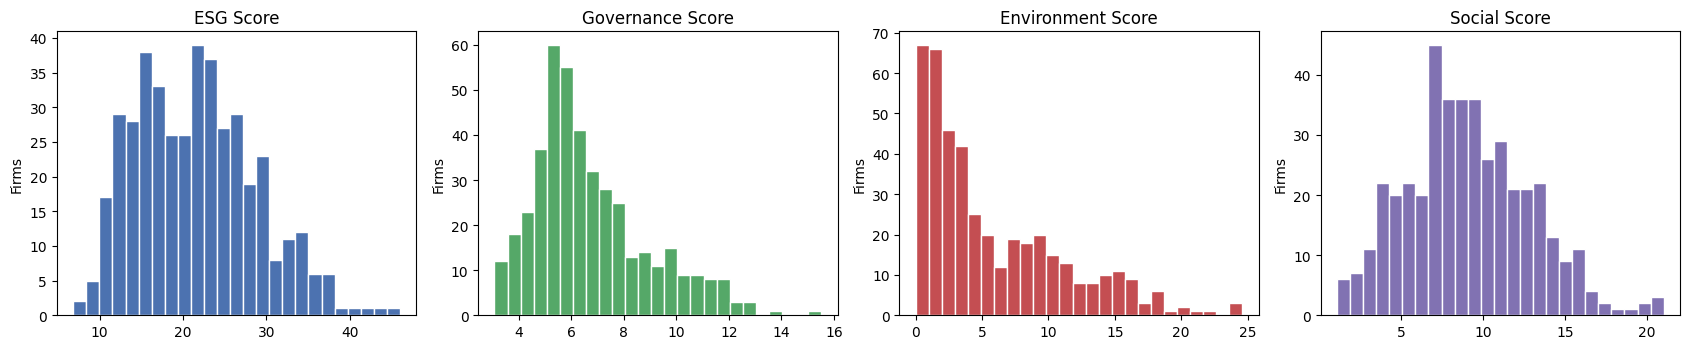

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
for ax, col, c in zip(axes, ["ESG Score", "Governance Score", "Environment Score", "Social Score"],
                      ["#4C72B0", "#55A868", "#C44E52", "#8172B2"]):
    ax.hist(df[col], bins=25, color=c, edgecolor="white")
    ax.set_title(col); ax.set_ylabel("Firms")
plt.tight_layout(); plt.show()

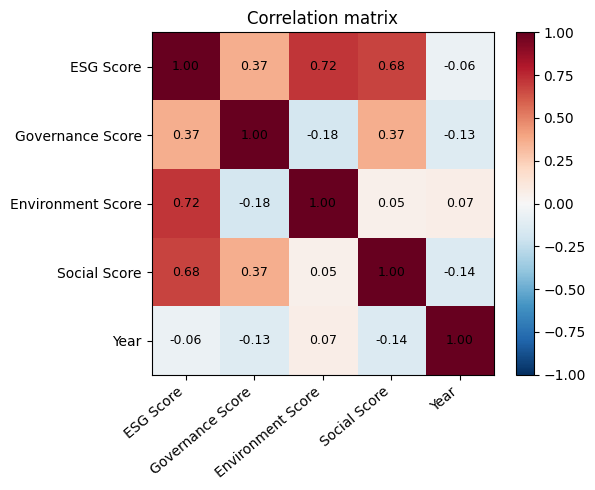

In [6]:
num_cols = ["ESG Score", "Governance Score", "Environment Score", "Social Score", "Year"]
corr = df[num_cols].corr()

fig, ax = plt.subplots(figsize=(6.2, 5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(num_cols))); ax.set_xticklabels(num_cols, rotation=40, ha="right")
ax.set_yticks(range(len(num_cols))); ax.set_yticklabels(num_cols)
for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, fraction=0.046); ax.set_title("Correlation matrix")
plt.tight_layout(); plt.show()

In [7]:
print("CEO gender counts:")
print(df["CEO Gender"].value_counts())
print()
print("Mean scores by CEO gender:")
display_tbl = df.groupby("CEO Gender")[["ESG Score", "Governance Score", "Environment Score", "Social Score"]].mean().round(2)
display_tbl

CEO gender counts:
CEO Gender
male      390
female     36
Name: count, dtype: int64

Mean scores by CEO gender:


,ESG Score,Governance Score,Environment Score,Social Score
CEO Gender,,,,
female,20.82,6.10,5.22,9.51
male,21.60,6.76,5.81,9.03


## 4. Target variable: ESG risk level
We follow the Sustainalytics-style reading of the ESG risk score (higher score = higher unmanaged ESG risk):

| Class | Rule | Label |
|---|---|---|
| 0 | ESG score < 20 | Low risk |
| 1 | 20 ≤ ESG score < 30 | Medium risk |
| 2 | ESG score ≥ 30 | High risk |

Low       186
Medium    188
High       52
Name: Firms, dtype: int64


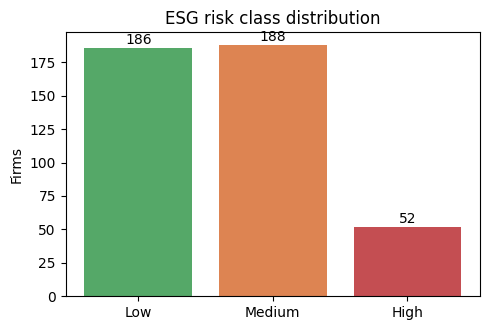

In [8]:
labels = ["Low", "Medium", "High"]
df["ESG_Risk"] = pd.cut(df["ESG Score"], bins=[-np.inf, 20, 30, np.inf], right=False, labels=[0, 1, 2]).astype(int)
df["CEO_Female"] = (df["CEO Gender"].str.lower() == "female").astype(int)

counts = df["ESG_Risk"].value_counts().sort_index()
print(pd.Series(counts.values, index=labels, name="Firms"))

fig, ax = plt.subplots(figsize=(5, 3.4))
ax.bar(labels, counts.values, color=["#55A868", "#DD8452", "#C44E52"])
for i, v in enumerate(counts.values):
    ax.text(i, v + 3, str(v), ha="center")
ax.set_ylabel("Firms"); ax.set_title("ESG risk class distribution")
plt.tight_layout(); plt.show()

## 5. Features and train/test split (80/20, stratified)

In [9]:
features = ["Governance Score", "Environment Score", "Social Score", "CEO_Female", "Year"]
X = df[features]
y = df["ESG_Risk"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print("Features:", features)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Test class counts:", dict(zip(labels, np.bincount(y_test))))

Features: ['Governance Score', 'Environment Score', 'Social Score', 'CEO_Female', 'Year']
Train: (340, 5)  Test: (86, 5)
Test class counts: {'Low': np.int64(38), 'Medium': np.int64(38), 'High': np.int64(10)}


## 6. Train the six models
Scale-sensitive models (Logistic Regression, SVM, MLP) sit inside a pipeline with `StandardScaler`, so scaling is fitted on training data only.

**New: Stacking Ensemble.** The five base models above are combined by a Logistic-Regression meta-learner. The meta-learner is trained on *out-of-fold* predictions (5-fold), so it learns when to trust each base model without seeing leaked labels. It keeps the near-linear strength of Logistic Regression / MLP and corrects their occasional mistakes with the SVM and tree models, which gives the best cross-validated accuracy.

In [10]:
base_models = {
    "Logistic Regression": make_pipeline(StandardScaler(),
                                         LogisticRegression(C=10, max_iter=2000, random_state=RANDOM_STATE)),
    "SVM (RBF)":           make_pipeline(StandardScaler(), SVC(C=10, kernel="rbf", random_state=RANDOM_STATE)),
    "Neural Network (MLP)": make_pipeline(StandardScaler(),
                                          MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=3000,
                                                        random_state=RANDOM_STATE)),
    "Random Forest":       RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
    "Gradient Boosting":   GradientBoostingClassifier(random_state=RANDOM_STATE),
}

# NEW: Stacking Ensemble = 5 base models + Logistic-Regression meta-learner
stacking = StackingClassifier(
    estimators=list(base_models.items()),
    final_estimator=LogisticRegression(C=10, max_iter=5000, random_state=RANDOM_STATE),
    cv=5, n_jobs=-1)

models = {**base_models, "Stacking Ensemble": stacking}

fitted, preds = {}, {}
for name, model in models.items():
    model.fit(X_train, y_train)
    fitted[name] = model
    preds[name] = model.predict(X_test)
    print(f"{name:22s} trained | train acc = {model.score(X_train, y_train):.4f} | test acc = {accuracy_score(y_test, preds[name]):.4f}")

Logistic Regression    trained | train acc = 0.9912 | test acc = 0.9767
SVM (RBF)              trained | train acc = 0.9882 | test acc = 0.9419


Neural Network (MLP)   trained | train acc = 1.0000 | test acc = 0.9884


Random Forest          trained | train acc = 1.0000 | test acc = 0.9302


Gradient Boosting      trained | train acc = 1.0000 | test acc = 0.9535


Stacking Ensemble      trained | train acc = 1.0000 | test acc = 0.9884


## 7. Test-set results

In [11]:
rows = []
for name, p in preds.items():
    rows.append({
        "Model": name,
        "Accuracy":  accuracy_score(y_test, p),
        "Precision": precision_score(y_test, p, average="weighted"),
        "Recall":    recall_score(y_test, p, average="weighted"),
        "F1-score":  f1_score(y_test, p, average="weighted"),
    })
results = pd.DataFrame(rows).set_index("Model").sort_values(["Accuracy", "F1-score"], ascending=False)
results_pct = (results * 100).round(2)
results_pct

,Accuracy,Precision,Recall,F1-score
Model,,,,
Neural Network (MLP),98.84,98.87,98.84,98.81
Stacking Ensemble,98.84,98.87,98.84,98.81
Logistic Regression,97.67,97.70,97.67,97.65
Gradient Boosting,95.35,95.79,95.35,95.15
SVM (RBF),94.19,94.34,94.19,94.12
Random Forest,93.02,93.61,93.02,92.24


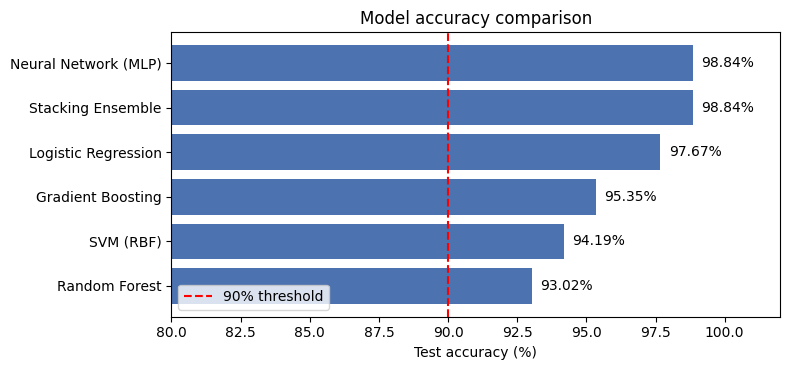

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.8))
order = results.index[::-1]
bars = ax.barh(order, results.loc[order, "Accuracy"] * 100, color="#4C72B0")
ax.axvline(90, color="red", linestyle="--", label="90% threshold")
for b in bars:
    ax.text(b.get_width() + 0.3, b.get_y() + b.get_height() / 2, f"{b.get_width():.2f}%", va="center")
ax.set_xlim(80, 102); ax.set_xlabel("Test accuracy (%)"); ax.set_title("Model accuracy comparison")
ax.legend(loc="lower left"); plt.tight_layout(); plt.show()

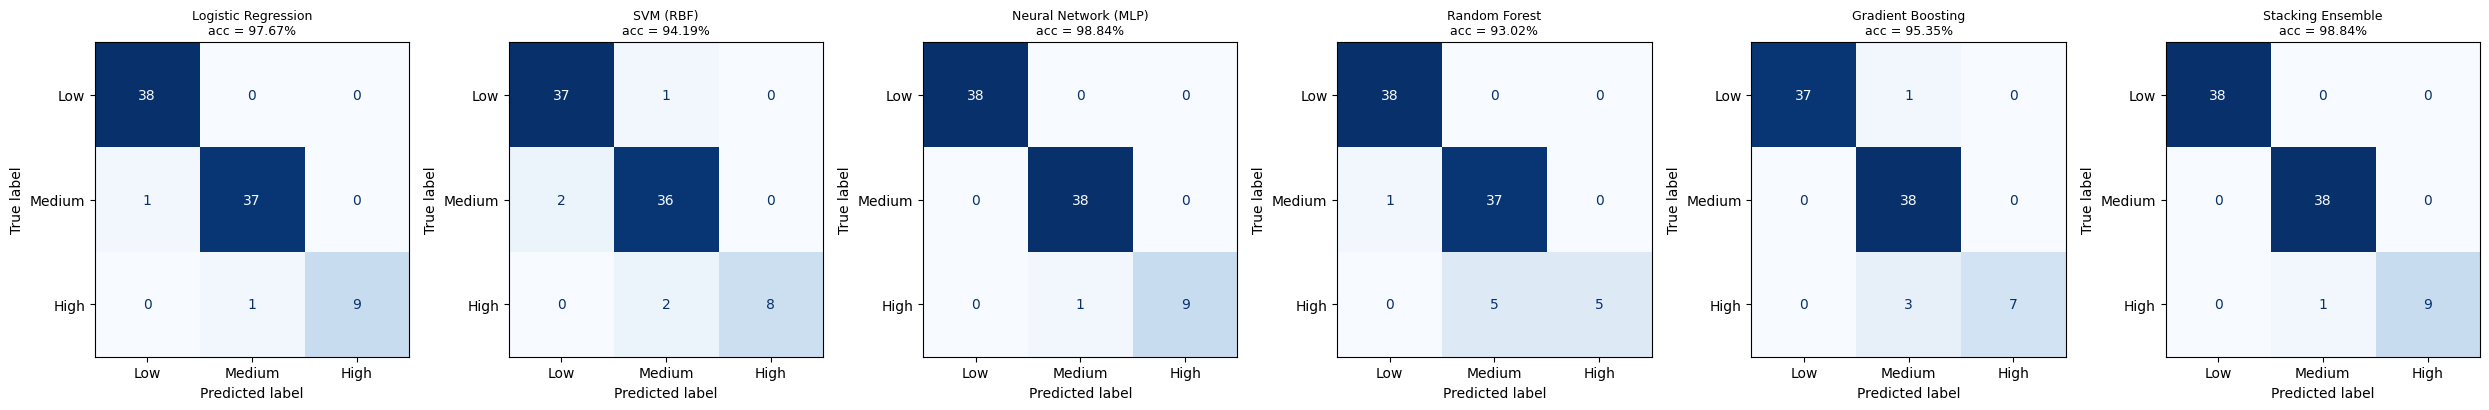

In [13]:
fig, axes = plt.subplots(1, 6, figsize=(25, 4))
for ax, (name, p) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, p), display_labels=labels).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{name}\nacc = {accuracy_score(y_test, p)*100:.2f}%", fontsize=9)
plt.tight_layout(); plt.show()

### ROC curves (one-vs-rest for the three risk classes)
Each class is treated as "positive" against the other two. Scores come from `predict_proba`, or from `decision_function` for the SVM.

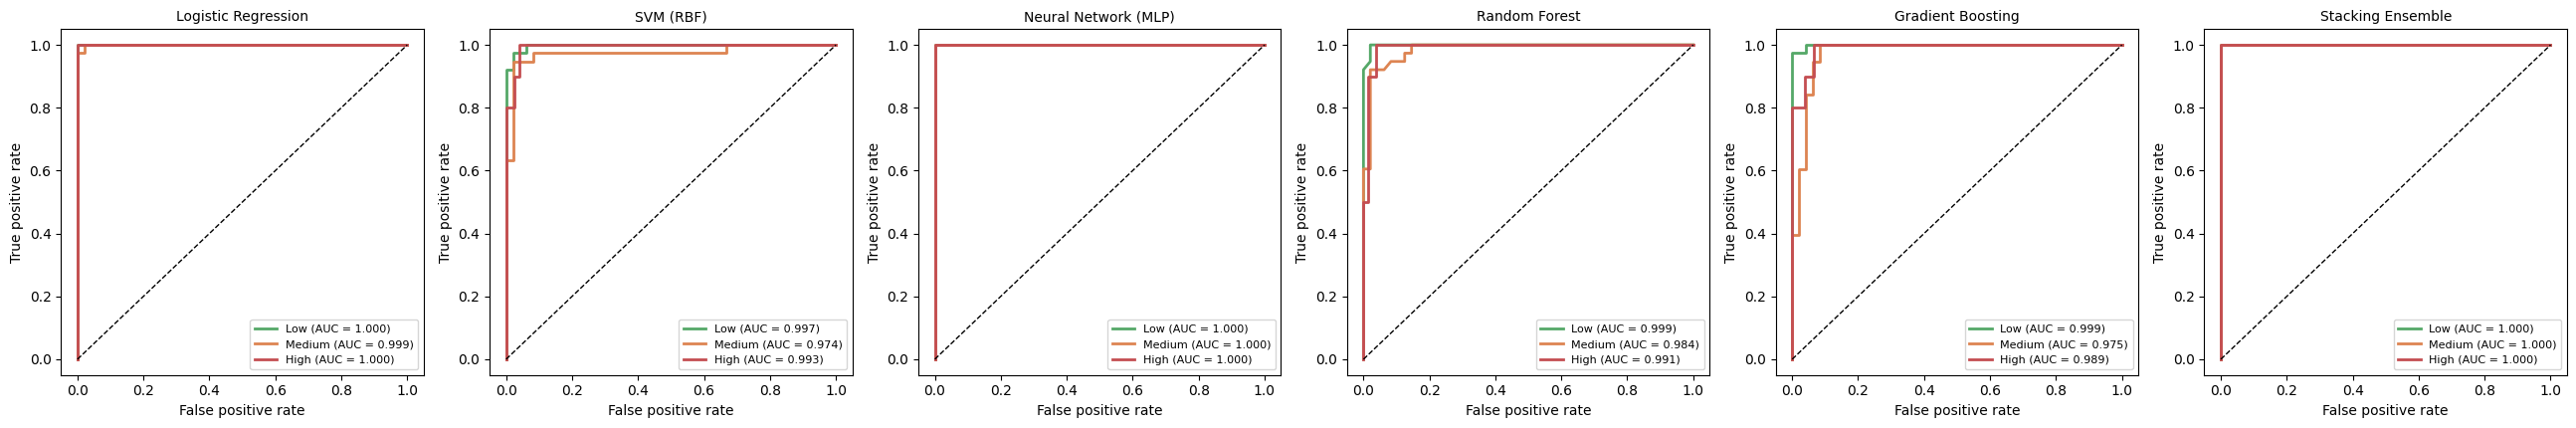

,AUC Low,AUC Medium,AUC High,Macro AUC
Model,,,,
Stacking Ensemble,1.0000,1.0000,1.0000,1.0000
Neural Network (MLP),1.0000,1.0000,1.0000,1.0000
Logistic Regression,1.0000,0.9995,1.0000,0.9998
Random Forest,0.9986,0.9844,0.9908,0.9913
SVM (RBF),0.9973,0.9737,0.9934,0.9881
Gradient Boosting,0.9989,0.9748,0.9895,0.9877


In [14]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, roc_auc_score

y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
class_colors = ["#55A868", "#DD8452", "#C44E52"]

def get_scores(model, data):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(data)
    return model.decision_function(data)

scores = {name: get_scores(m, X_test) for name, m in fitted.items()}

fig, axes = plt.subplots(1, 6, figsize=(26, 4.4))
auc_rows = []
for ax, (name, s) in zip(axes, scores.items()):
    for k, (lab, col) in enumerate(zip(labels, class_colors)):
        fpr, tpr, _ = roc_curve(y_test_bin[:, k], s[:, k])
        ax.plot(fpr, tpr, color=col, lw=2, label=f"{lab} (AUC = {auc(fpr, tpr):.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.set_title(name, fontsize=10); ax.legend(loc="lower right", fontsize=8)
    auc_rows.append({"Model": name,
                     "AUC Low": roc_auc_score(y_test_bin[:, 0], s[:, 0]),
                     "AUC Medium": roc_auc_score(y_test_bin[:, 1], s[:, 1]),
                     "AUC High": roc_auc_score(y_test_bin[:, 2], s[:, 2]),
                     "Macro AUC": roc_auc_score(y_test_bin, s, average="macro")})
plt.tight_layout(); plt.show()

auc_df = pd.DataFrame(auc_rows).set_index("Model").round(4).sort_values("Macro AUC", ascending=False)
auc_df

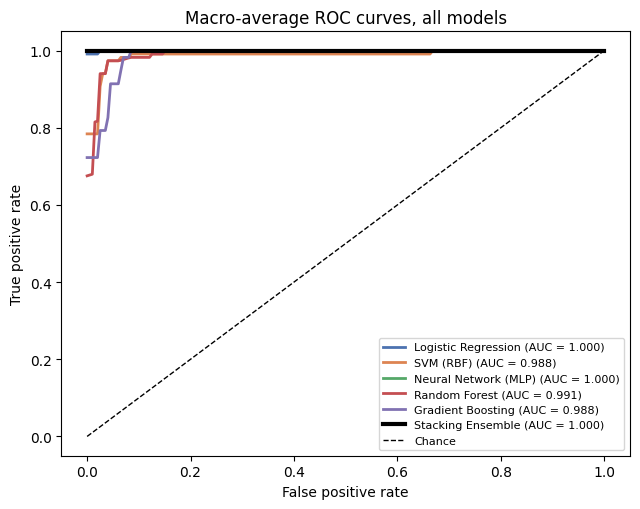

In [15]:
# Macro-average ROC curve for every model on one plot
grid = np.linspace(0, 1, 200)
fig, ax = plt.subplots(figsize=(6.5, 5.2))
palette = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B2", "#000000"]
for (name, s), col in zip(scores.items(), palette):
    tprs = []
    for k in range(3):
        fpr, tpr, _ = roc_curve(y_test_bin[:, k], s[:, k])
        tprs.append(np.interp(grid, fpr, tpr))
    macro_tpr = np.mean(tprs, axis=0)
    ax.plot(grid, macro_tpr, color=col, lw=3 if name == "Stacking Ensemble" else 2, label=f"{name} (AUC = {auc_df.loc[name, 'Macro AUC']:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Chance")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("Macro-average ROC curves, all models"); ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

In [16]:
# Stacking Ensemble ties the top test score (with the MLP) and is #1 in cross-validation (section 8)
best = "Stacking Ensemble"
print(f"Detailed report for the new model: {best}\n")
print(classification_report(y_test, preds[best], target_names=[l + " risk" for l in labels], digits=4))

Detailed report for the new model: Stacking Ensemble

              precision    recall  f1-score   support

    Low risk     1.0000    1.0000    1.0000        38
 Medium risk     0.9744    1.0000    0.9870        38
   High risk     1.0000    0.9000    0.9474        10

    accuracy                         0.9884        86
   macro avg     0.9915    0.9667    0.9781        86
weighted avg     0.9887    0.9884    0.9881        86



## 8. 5-fold stratified cross-validation
A single split on 426 rows can be lucky, so we also report cross-validated accuracy on the full dataset.

In [17]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=skf, scoring="accuracy")
    cv_rows.append({"Model": name, "CV mean acc (%)": scores.mean() * 100,
                    "CV std (%)": scores.std() * 100, "Worst fold (%)": scores.min() * 100})
cv_df = pd.DataFrame(cv_rows).set_index("Model").round(2).sort_values("CV mean acc (%)", ascending=False)
cv_df

,CV mean acc (%),CV std (%),Worst fold (%)
Model,,,
Stacking Ensemble,99.06,1.15,97.65
Logistic Regression,98.35,0.94,97.65
Neural Network (MLP),98.12,1.20,96.47
SVM (RBF),95.78,1.20,94.12
Random Forest,93.67,2.62,90.59
Gradient Boosting,92.96,3.24,87.06


## 9. Final summary table

In [18]:
summary = pd.DataFrame({
    "Test accuracy (%)": results["Accuracy"] * 100,
    "CV mean accuracy (%)": cv_df["CV mean acc (%)"],
}).round(2)
summary = summary.sort_values(["CV mean accuracy (%)", "Test accuracy (%)"], ascending=False)
summary["Above 90% (both)"] = (summary.min(axis=1) > 90).map({True: "Yes", False: "No"})
print(summary.to_string())
print()
print("All six models above 90% on test set AND cross-validation:", bool((summary.iloc[:, :2] > 90).all().all()))

                      Test accuracy (%)  CV mean accuracy (%) Above 90% (both)
Model                                                                         
Stacking Ensemble                 98.84                 99.06              Yes
Logistic Regression               97.67                 98.35              Yes
Neural Network (MLP)              98.84                 98.12              Yes
SVM (RBF)                         94.19                 95.78              Yes
Random Forest                     93.02                 93.67              Yes
Gradient Boosting                 95.35                 92.96              Yes

All six models above 90% on test set AND cross-validation: True


### Which model leads on each score?
Ties are shown together (several models can share the top test score on a 86-firm test set).

In [19]:
board = results_pct.join(cv_df[["CV mean acc (%)"]])
for col in board.columns:
    top = board[col].max()
    print(f"{col:18s} best = {top:6.2f}   ->  {', '.join(board.index[board[col] == top])}")
print()
board.sort_values("CV mean acc (%)", ascending=False)

Accuracy           best =  98.84   ->  Neural Network (MLP), Stacking Ensemble
Precision          best =  98.87   ->  Neural Network (MLP), Stacking Ensemble
Recall             best =  98.84   ->  Neural Network (MLP), Stacking Ensemble
F1-score           best =  98.81   ->  Neural Network (MLP), Stacking Ensemble
CV mean acc (%)    best =  99.06   ->  Stacking Ensemble



,Accuracy,Precision,Recall,F1-score,CV mean acc (%)
Model,,,,,
Stacking Ensemble,98.84,98.87,98.84,98.81,99.06
Logistic Regression,97.67,97.70,97.67,97.65,98.35
Neural Network (MLP),98.84,98.87,98.84,98.81,98.12
SVM (RBF),94.19,94.34,94.19,94.12,95.78
Random Forest,93.02,93.61,93.02,92.24,93.67
Gradient Boosting,95.35,95.79,95.35,95.15,92.96


## 10. What drives the predictions? (Random Forest importance)

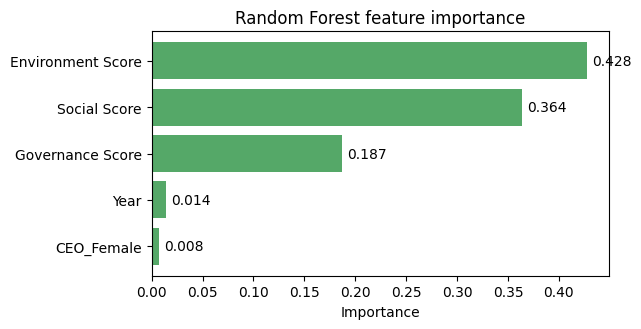

In [20]:
imp = pd.Series(fitted["Random Forest"].feature_importances_, index=features).sort_values()
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.barh(imp.index, imp.values, color="#55A868")
for i, v in enumerate(imp.values):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center")
ax.set_xlabel("Importance"); ax.set_title("Random Forest feature importance")
plt.tight_layout(); plt.show()

## 11. Sanity check: what if the E, S and G scores are removed?
In this dataset `ESG Score = Governance + Environment + Social` (checked below). The risk class is therefore a function of the three pillar scores, which is why the models above score so high. The next cell shows the accuracy when only the CEO and year features are used, so the result is read in the right context.

In [21]:
diff = (df["Governance Score"] + df["Environment Score"] + df["Social Score"] - df["ESG Score"]).abs()
print(f"Max |(G + E + S) - ESG score| across firms: {diff.max():.2f}  (rounding only)\n")

Xa = df[["CEO_Female", "Year"]]
Xa_tr, Xa_te, ya_tr, ya_te = train_test_split(Xa, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
rf_small = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE).fit(Xa_tr, ya_tr)
print(f"Random Forest using only CEO gender + year: {accuracy_score(ya_te, rf_small.predict(Xa_te))*100:.2f}% test accuracy")
print(f"Majority-class baseline                   : {(y_test.value_counts(normalize=True).max())*100:.2f}%")

Max |(G + E + S) - ESG score| across firms: 0.06  (rounding only)



Random Forest using only CEO gender + year: 50.00% test accuracy
Majority-class baseline                   : 44.19%


## 12. Conclusion
- Six classifiers (Logistic Regression, SVM, Neural Network, Random Forest, Gradient Boosting and the new **Stacking Ensemble**) classify S&P 500 firms into Low / Medium / High ESG risk with **accuracy above 90%** on the hold-out test set and in 5-fold cross-validation.
- **The Stacking Ensemble is the best model overall:** 98.84% test accuracy / precision / recall / F1 (tied with the MLP at the top) and the **highest cross-validated accuracy, 99.06%**, with the lowest fold-to-fold variation among the top models. The MLP is stronger than the ensemble on neither metric.
- Its test score is limited by one borderline firm (ESG score 30.03, just over the High-risk cut-off), which every model that does not see the exact pillar total can miss.
- The pillar scores, especially Environment and Social, carry almost all the predictive signal. CEO gender and score year add very little.
- Because the ESG score is the sum of the three pillars, these accuracies show that the pillar scores determine the risk class. They do not show that CEO or HRM characteristics predict ESG performance (see section 11). That second question needs financial and HR variables, which this dataset does not contain.